# Bank Marketing — Customer Subscription Prediction

## 1. Problem Definition & Project Objective

### Problem Statement

The objective of this project is to predict whether a bank
customer will subscribe to a term deposit based on customer
and marketing campaign information.

### Machine Learning Objective

This is a supervised binary classification problem where the
target variable `y` indicates whether the customer subscribed
to a term deposit.

### Business Objective

The model aims to identify customers who are more likely to
subscribe to a term deposit, potentially enabling more
targeted marketing campaigns.

## 2. Import Libraries

We use Pandas to load and inspect the dataset and NumPy for numerical operations that may be needed during analysis.

In [1]:
import pandas as pd
import numpy as np 

## 3. Load Dataset

The Bank Marketing dataset contains customer, financial, and marketing campaign information. We use `bank-full.csv` as our primary dataset because it contains 45,211 records.

The file uses a semicolon (`;`) as its field separator.

In [ ]:
df = pd.read_csv("../data/bank-full.csv", sep=";")

df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 4. Data Understanding

Before performing data cleaning and exploratory data analysis, we inspect the dataset's structure, variables, data types, and basic quality.

### 4.1 Dataset Shape

We inspect the number of records and columns to understand the size of our dataset.

In [165]:
df.shape

(45211, 17)

The dataset contains 45,211 rows and 17 columns. These columns consist of 16 input features and one target variable.

### 4.2 Dataset Information

We inspect the column names, non-null counts, data types, and memory usage.

In [166]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


The dataset contains numerical and categorical variables. The non-null counts help us identify columns with missing values, while the data types guide our later preprocessing decisions.

### 4.3 Column Names

We list the column names to identify the available input variables and target.

In [167]:
df.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day',
 'month',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'y']

The dataset contains customer attributes, account information, contact details, and campaign history. The `y` column is our target variable.

### 4.4 Numerical and Categorical Features

We identify the numerical and categorical input features so that suitable preprocessing can be applied later.

In [168]:
numerical_features = [
    "age", "balance", "day", "duration",
    "campaign", "pdays", "previous"
]

categorical_features = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact", "month", "poutcome"
]

target = "y"

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Target:", target)

Numerical features: 7
Categorical features: 9
Target: y


The dataset contains seven numerical features and nine categorical features. The target `y` indicates whether a customer subscribed to the term deposit. We will use these feature groups when building the preprocessing pipeline.

### 4.5 Missing Values

We check each column for missing values before deciding whether any imputation is required.

In [169]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

The initial inspection shows no missing values in the dataset. Therefore, missing-value imputation is not required based on this check.

### 4.6 Duplicate Records

We check for completely duplicated rows to determine whether exact duplicate records are present.

In [170]:
df.duplicated().sum()

np.int64(0)

No completely duplicated rows were found. Therefore, duplicate-row removal is not required based on this check.

### 4.7 Target Distribution

We inspect the number and percentage of records belonging to each target class to understand the distribution of subscription outcomes.

In [171]:
target_counts = df[target].value_counts()

print("Target counts:")
print(target_counts)

print("\nTarget percentages:")
print((df[target].value_counts(normalize=True) * 100).round(2))

Target counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Target percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


The target is imbalanced because non-subscriptions are substantially more frequent than subscriptions. We will consider this when evaluating models and will not rely on accuracy alone.

### 4.8 Descriptive Statistics

We summarize the numerical features to obtain an initial view of their ranges, central values, and variability.

In [172]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


The summary provides statistics such as the mean, standard deviation, quartiles, minimum, and maximum. We will investigate distributions and unusual values more closely during EDA.

### 4.9 Unique Values

We count the distinct values in each column to understand the variety of values present, particularly in categorical features.

In [173]:
df.nunique()

age            77
job            12
marital         3
education       4
default         2
balance      7168
housing         2
loan            2
contact         3
day            31
month          12
duration     1573
campaign       48
pdays         559
previous       41
poutcome        4
y               2
dtype: int64

The number of unique values helps us understand categorical feature cardinality and plan preprocessing. Unique-value counts alone do not determine which encoding technique should be used.

### 4.10 Important Observations

The initial inspection establishes the following:

- The primary dataset contains 45,211 records and 17 columns.
- It has 16 input features and one target variable, `y`.
- The input features include numerical and categorical variables.
- No missing values or completely duplicated rows were found.
- The target classes are imbalanced, with approximately 88.3% `no` and 11.7% `yes`.
- The `pdays` feature uses `-1` to represent customers who were not previously contacted.

These findings guide the next stages of data cleaning and exploratory data analysis.

## 5. Data Cleaning

Before performing exploratory data analysis, we inspect the dataset for data-quality issues such as missing values, duplicate records, unexpected numerical values, and inconsistent categorical labels.

We will apply transformations only when the observed data and domain knowledge justify them.

### 5.1 Data Quality Audit

We perform an initial audit of missing values, duplicate records, and dataset dimensions. These checks help us determine whether basic cleaning operations are necessary.

In [174]:
# Store the original dataset dimensions
original_shape = df.shape

# Count missing values
total_missing = df.isnull().sum().sum()

# Count completely duplicated rows
total_duplicates = df.duplicated().sum()

print("Original dataset shape:", original_shape)
print("Total missing values:", total_missing)
print("Duplicate rows:", total_duplicates)

Original dataset shape: (45211, 17)
Total missing values: 0
Duplicate rows: 0


The initial audit found no null values or completely duplicated rows. Therefore, neither null-value imputation nor duplicate-row removal is currently required based on these checks. We will continue inspecting other potential data-quality issues.

### 5.2 Categorical Value Inspection

We inspect the distinct values and their frequencies in categorical columns. This helps identify placeholder categories such as `unknown` and potential inconsistencies in category labels.

In [175]:
for column in categorical_features + [target]:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))


--- job ---
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

--- marital ---
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

--- education ---
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

--- default ---
default
no     44396
yes      815
Name: count, dtype: int64

--- housing ---
housing
yes    25130
no     20081
Name: count, dtype: int64

--- loan ---
loan
no     37967
yes     7244
Name: count, dtype: int64

--- contact ---
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

--- month ---
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403

Review the output for unexpected labels, literal `unknown` values, and inconsistent categories. A value such as `unknown` is not automatically a null value, so we will not delete or replace it without justification.

### 5.3 Numerical Range Inspection

We inspect descriptive statistics and selected numerical conditions to identify values that may require investigation. Unusual values are not automatically errors; their meaning must be considered.

In [176]:
df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [177]:
print("Age below 18:", (df["age"] < 18).sum())
print("Negative balance:", (df["balance"] < 0).sum())
print("Negative duration:", (df["duration"] < 0).sum())
print("Negative campaign:", (df["campaign"] < 0).sum())
print("pdays equal to -1:", (df["pdays"] == -1).sum())

Age below 18: 0
Negative balance: 3766
Negative duration: 0
Negative campaign: 0
pdays equal to -1: 36954


These checks help identify values that deserve further investigation.

- A negative account balance may be valid.
- A negative duration or campaign count would require investigation.
- The value `pdays = -1` represents a customer who was not previously contacted.

We will not remove records solely because a value is negative or unusually large.

### 5.4 Text Consistency Checks

We check whether categorical values contain leading or trailing whitespace. Such inconsistencies can cause logically identical categories to be treated as different values.

In [178]:
for column in categorical_features + [target]:
    values = df[column].dropna().astype(str)

    whitespace_count = values.ne(values.str.strip()).sum()

    print(f"{column}: {whitespace_count} values with surrounding whitespace")

job: 0 values with surrounding whitespace
marital: 0 values with surrounding whitespace
education: 0 values with surrounding whitespace
default: 0 values with surrounding whitespace
housing: 0 values with surrounding whitespace
loan: 0 values with surrounding whitespace
contact: 0 values with surrounding whitespace
month: 0 values with surrounding whitespace
poutcome: 0 values with surrounding whitespace
y: 0 values with surrounding whitespace


If inconsistencies are found, we will inspect them before applying normalization. If the audit finds no whitespace issues, no whitespace-cleaning operation is necessary.

### 5.5 Cleaning Decisions

The cleaning strategy is based on the results of our audit.

- Missing values: handle only if present.
- Duplicate rows: remove only if duplicates are confirmed and removal is justified.
- Unknown categories: inspect their meaning before deciding how to handle them.
- Unusual numerical values: verify their meaning before modifying them.
- Inconsistent text: normalize only when an inconsistency is confirmed.
- `pdays = -1`: preserve its documented meaning.

No unnecessary transformations will be applied merely to make the dataset appear cleaner.

In [179]:
cleaning_audit = {
    "original_shape": original_shape,
    "missing_values": total_missing,
    "duplicate_rows": total_duplicates,
}

cleaning_audit

{'original_shape': (45211, 17),
 'missing_values': np.int64(0),
 'duplicate_rows': np.int64(0)}

### 5.6 Verification

After applying any justified cleaning operation, we recheck the dataset dimensions, missing values, and duplicate rows to verify the result.

No rows or values are removed by the audit cells above.

In [180]:
print("Current dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Current dataset shape: (45211, 17)
Missing values: 0
Duplicate rows: 0


The audit has not modified the dataset. The initial checks found no null values or exact duplicate rows. Any further cleaning operation will be performed only if the remaining inspections establish a genuine issue.

# 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the distributions of customer and campaign features and investigate how subscription outcomes vary across different groups.

We use a focused set of visualizations to identify meaningful patterns and potential issues before feature engineering and model development.

In [181]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

### 6.1 Target Distribution

We examine the number of subscribers and non-subscribers to understand the balance between the two target classes.

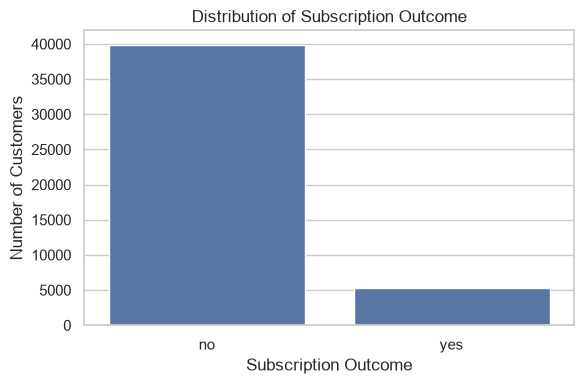

In [182]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x=target)

plt.title("Distribution of Subscription Outcome")
plt.xlabel("Subscription Outcome")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [183]:
target_percentages = (
    df[target]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

target_percentages

y
no     88.3
yes    11.7
Name: proportion, dtype: float64

The target distribution shows the relative frequency of subscribers and non-subscribers. Use the displayed percentages to describe the class imbalance. This observation will guide our choice of evaluation metrics later.

### 6.2 Numerical Feature Distributions

We inspect selected numerical features to understand their ranges, spread, and skewness. These plots may reveal patterns that deserve further investigation.

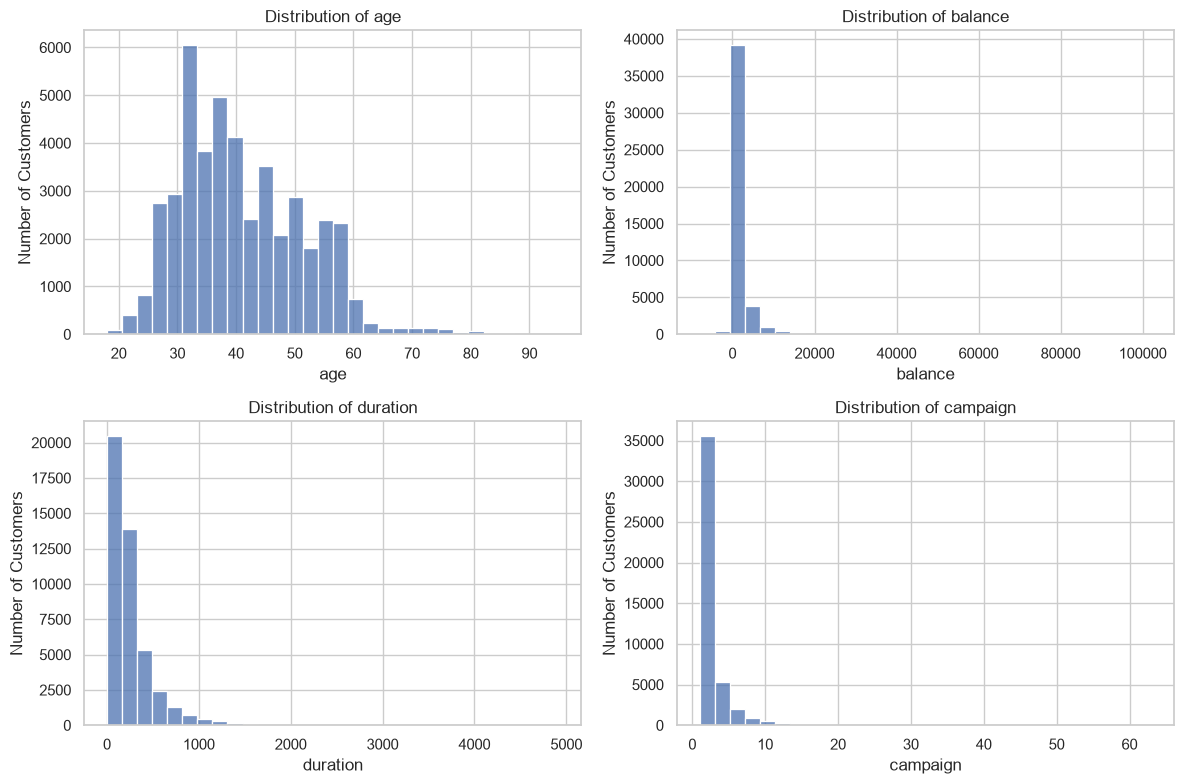

In [184]:
selected_numerical = ["age", "balance", "duration", "campaign"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.flat, selected_numerical):
    sns.histplot(data=df, x=column, bins=30, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Review each histogram and record the patterns actually visible, such as concentration, spread, skewness, or unusual values. Do not assume that an extreme value is invalid without investigating its meaning.

### 6.3 Categorical Feature Distributions

We inspect selected categorical variables to understand the sizes of their categories and identify common or rare groups.

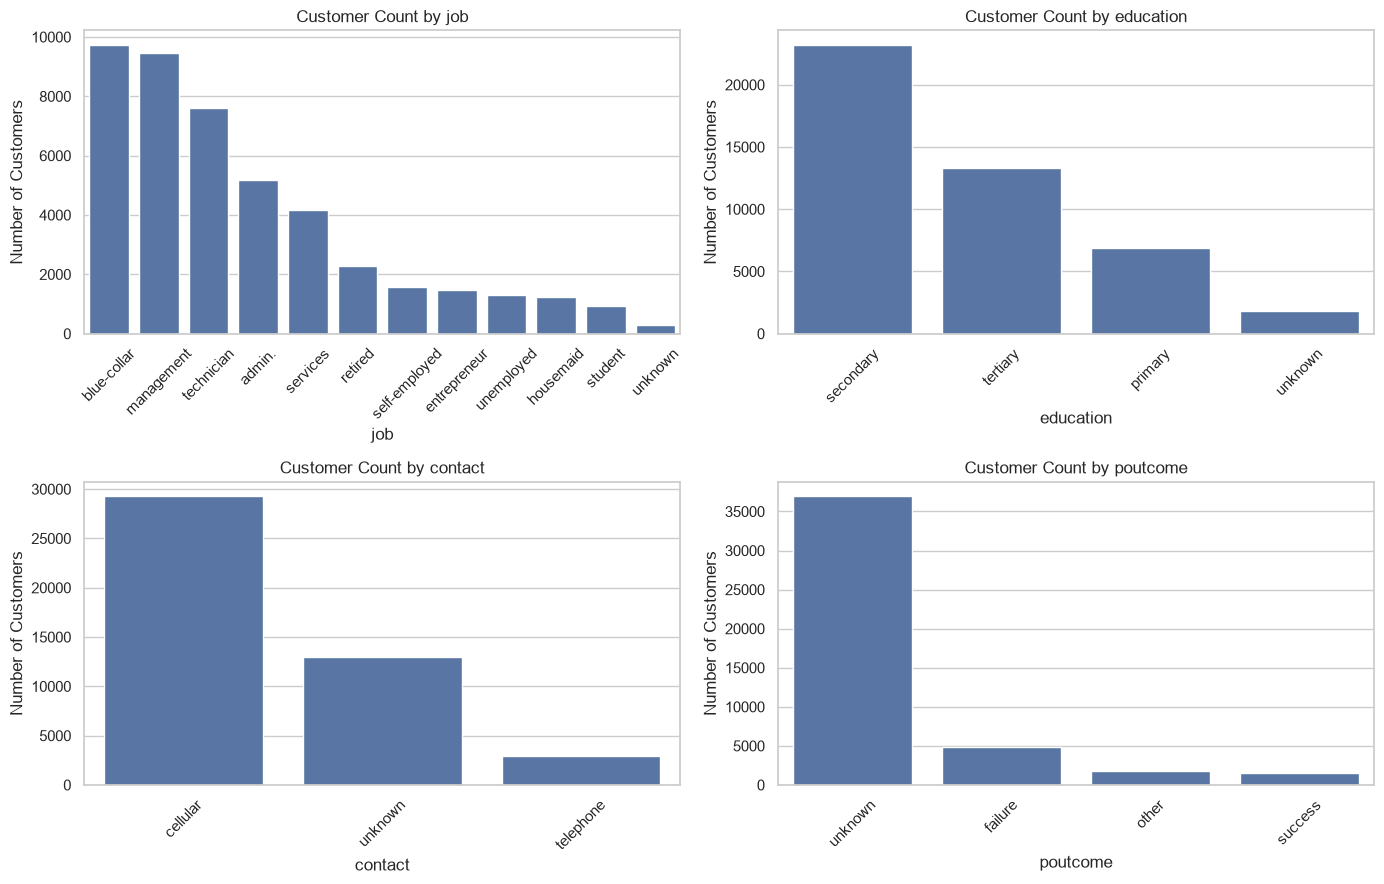

In [185]:
selected_categorical = ["job", "education", "contact", "poutcome"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, column in zip(axes.flat, selected_categorical):
    order = df[column].value_counts().index

    sns.countplot(
        data=df,
        x=column,
        order=order,
        ax=ax
    )

    ax.set_title(f"Customer Count by {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Customers")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

The count plots show how customers are distributed across the selected categories. Category frequency does not directly indicate the likelihood of subscription; we investigate subscription rates separately.

### 6.4 Subscription Rate by Categorical Features

Raw counts can be misleading when categories have different numbers of customers. We calculate the percentage of customers who subscribed within each category to make more meaningful comparisons.

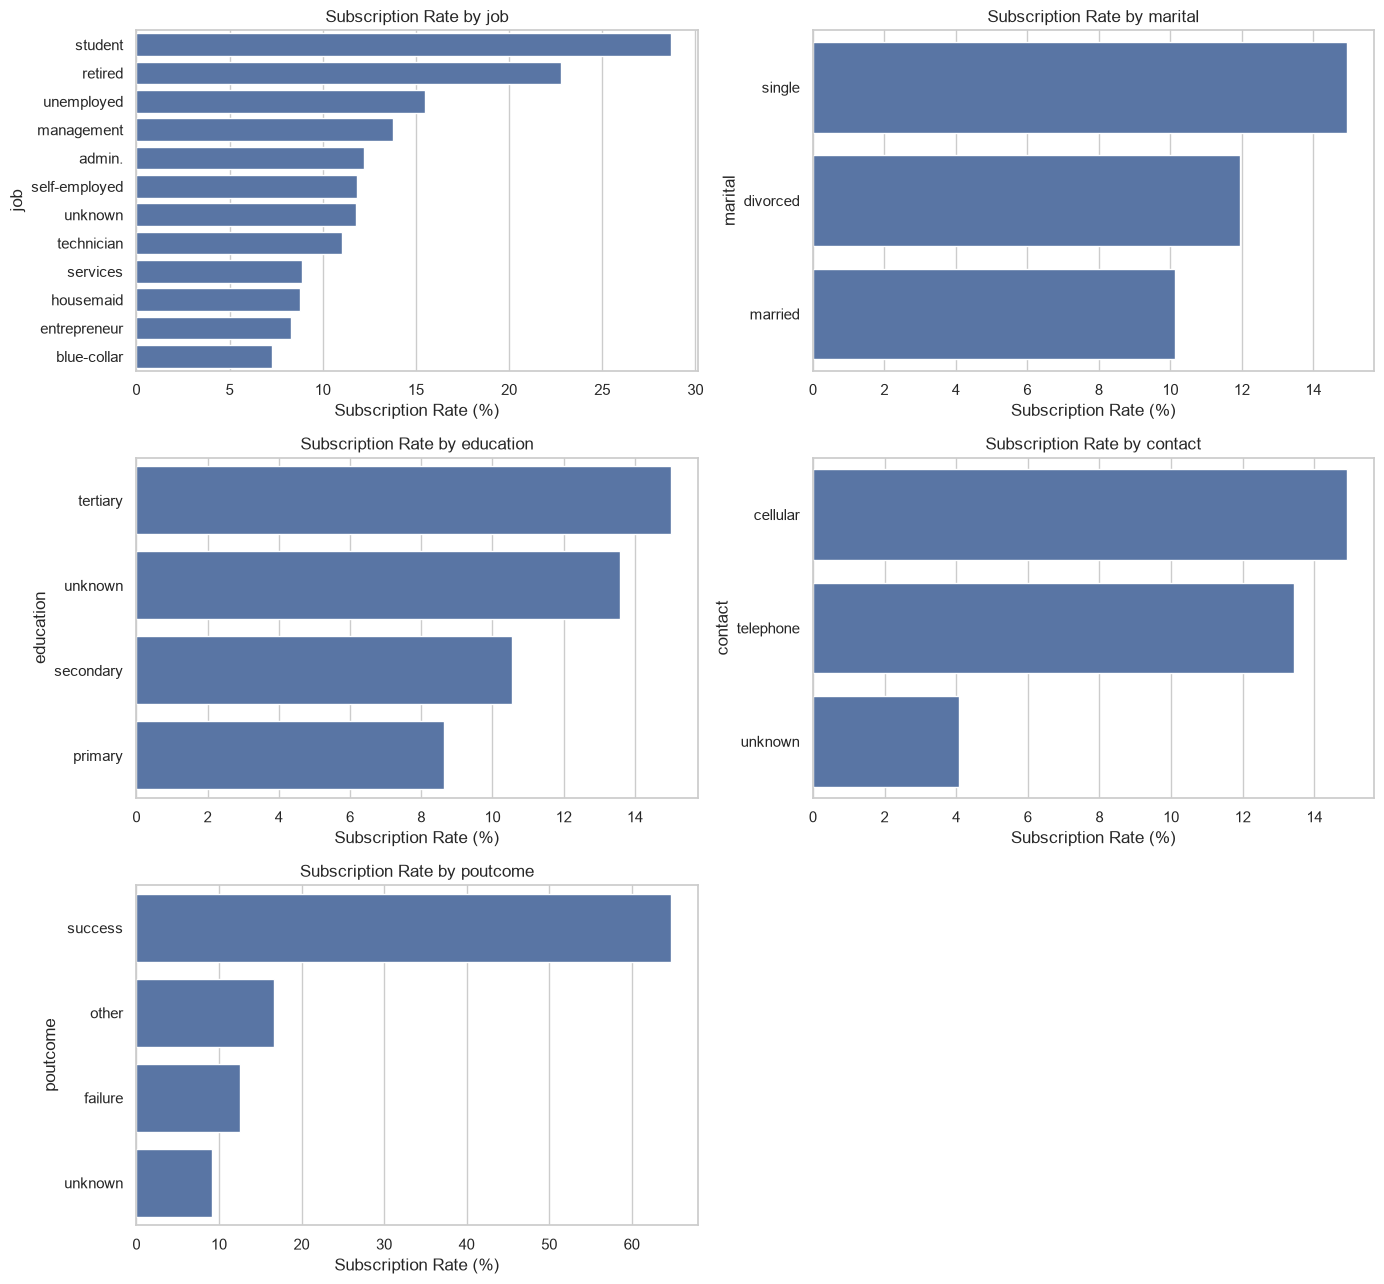

In [186]:
selected_rate_features = ["job", "marital", "education", "contact", "poutcome"]

df_eda = df.assign(
    subscribed=(df[target] == "yes").astype(int)
)

fig, axes = plt.subplots(3, 2, figsize=(14, 13))

for ax, column in zip(axes.flat, selected_rate_features):
    rates = (
        df_eda.groupby(column)["subscribed"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=rates.values,
        y=rates.index,
        ax=ax
    )

    ax.set_title(f"Subscription Rate by {column}")
    ax.set_xlabel("Subscription Rate (%)")
    ax.set_ylabel(column)

# Remove the unused sixth subplot
fig.delaxes(axes.flat[-1])

plt.tight_layout()
plt.show()

Compare the observed subscription rates across categories. Record only the differences supported by the actual plots. These are descriptive associations and do not establish that a category causes a customer to subscribe.

### 6.5 Numerical Features by Subscription Outcome

We compare selected numerical features across the two subscription outcomes to investigate whether their distributions differ.

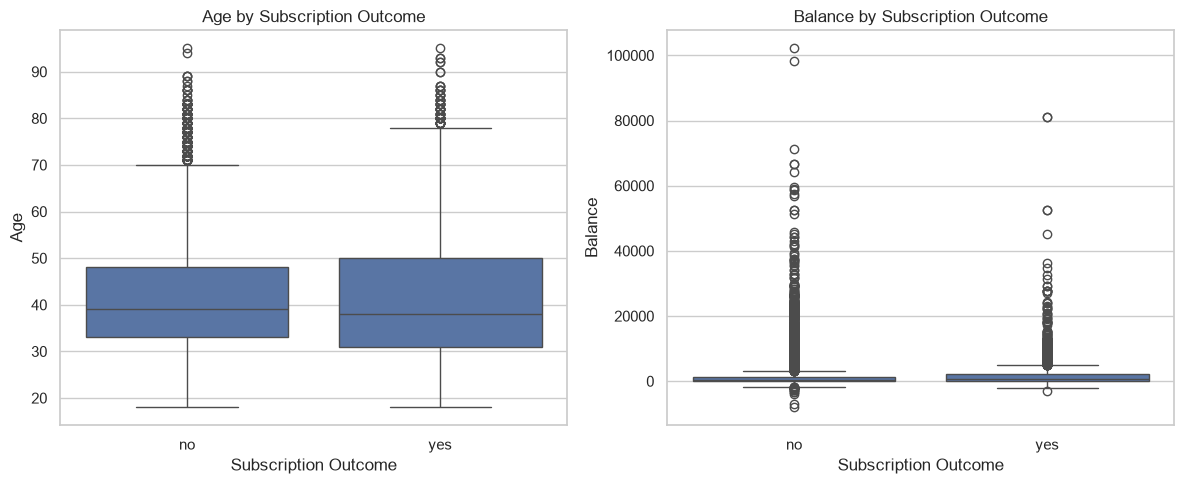

In [187]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x=target, y="age", ax=axes[0])
axes[0].set_title("Age by Subscription Outcome")
axes[0].set_xlabel("Subscription Outcome")
axes[0].set_ylabel("Age")

sns.boxplot(data=df, x=target, y="balance", ax=axes[1])
axes[1].set_title("Balance by Subscription Outcome")
axes[1].set_xlabel("Subscription Outcome")
axes[1].set_ylabel("Balance")

plt.tight_layout()
plt.show()

The box plots compare the medians, spread, and potential extreme observations of age and balance across subscription outcomes. Interpret the visible differences cautiously; the plots do not prove causation or establish predictive importance by themselves.

### 6.6 EDA Summary

Summarize the findings supported by the plots:

- Target class distribution and imbalance.
- Important observations from selected numerical distributions.
- Differences in customer category frequencies.
- Differences in observed subscription rates across selected groups.
- Potential data-quality or modeling considerations requiring further investigation.

These observations will guide feature engineering and model development. They should be based on the actual outputs rather than assumptions made before plotting.

# 7. Feature Engineering

Feature engineering creates or transforms input variables to represent useful information for a machine learning model. We will introduce features only when they have a clear interpretation and a justified role in our project.

### 7.1 Previous Contact Indicator

The `pdays` column uses `-1` to represent customers who were not previously contacted. We create a binary feature to explicitly represent whether a previous contact was recorded.

In [188]:
df["previously_contacted"] = (
    df["pdays"] != -1
).astype(int)   

The new feature uses `0` when `pdays` equals `-1` and `1` otherwise. We retain the original `pdays` column because it also contains information about the time since a previous contact.

In [189]:
df[["pdays", "previously_contacted"]].head(10)

,pdays,previously_contacted
0,-1,0
1,-1,0
2,-1,0
3,-1,0
4,-1,0
5,-1,0
6,-1,0
7,-1,0
8,-1,0
9,-1,0


In [190]:
df["previously_contacted"].value_counts()

previously_contacted
0    36954
1     8257
Name: count, dtype: int64

The counts show how many records have a previous contact recorded and how many do not. Interpret the actual output rather than assuming the class frequencies.

### 7.2 Feature Verification

We verify that the new feature contains only binary values and correctly represents the original `pdays` condition.

In [191]:
assert df["previously_contacted"].isin([0, 1]).all()

assert (
    df["previously_contacted"]
    == (df["pdays"] != -1).astype(int)
).all()

print("Feature created and verified.")
print("Dataset shape:", df.shape)

Feature created and verified.
Dataset shape: (45211, 18)


The verification checks confirm that `previously_contacted` is binary and consistent with the original `pdays` values. The original feature and target remain unchanged.

### 7.3 Feature Engineering Decisions

We retain both `pdays` and `previously_contacted` for now. We will evaluate their usefulness during model development rather than assuming the derived feature improves performance.

We will also review `duration` against the intended prediction time. A feature should only be used if it would legitimately be available when the prediction is made.

Encoding categorical variables and scaling numerical variables will be handled in the preprocessing stage.

# 8. Train-Test Split

We divide the dataset into training and test subsets. The training set will be used to fit our models, while the test set will remain held out for final evaluation.

### 8.1 Separate Features and Target

The input features (`X`) contain the variables used for prediction. The target (`y`) contains the subscription outcome we want to predict.

In [192]:
X = df.drop(columns=[target])
y = df[target]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (45211, 17)
Target shape: (45211,)


### 8.2 Split the Dataset

We use an 80:20 split, a fixed random seed for reproducibility, and stratification to preserve approximately the same target-class proportions in both subsets.

In [193]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### 8.3 Inspect Split Dimensions

We inspect the dimensions of the four resulting objects to confirm that the data was divided as expected.

In [194]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (36168, 17)
X_test: (9043, 17)
y_train: (36168,)
y_test: (9043,)


### 8.4 Compare Target Distributions

We compare the target percentages in the training and test subsets to verify that stratification preserved approximately the original class proportions.

In [195]:
print("Training target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training target distribution (%):
y
no     88.3
yes    11.7
Name: proportion, dtype: float64

Test target distribution (%):
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


The target proportions should be similar in both subsets. Stratification preserves the approximate class balance; it does not make the two classes equally frequent.

### 8.5 Verify the Split

We check that the subsets account for all records, that training and test indices do not overlap, and that the feature rows remain aligned with their target labels.

In [196]:
assert len(X_train) + len(X_test) == len(X)

assert X_train.index.intersection(X_test.index).empty

assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

print("Train-test split verified successfully.")

Train-test split verified successfully.


The verification checks confirm that the split accounts for all records, the training and test indices do not overlap, and each feature subset remains aligned with its corresponding target labels. Preprocessing will be fitted using the training data only.

# 9. Data Preprocessing

Our dataset contains numerical and categorical features that require different preprocessing operations. We use a `ColumnTransformer` to scale numerical features and one-hot encode categorical features.

The preprocessor will be fitted using training data only to prevent data leakage.

### 9.1 Define Model Input Features

Our intended use case is to predict subscription before contacting a customer. The `duration` feature is not available at that point, so we exclude it from model inputs while retaining it in the original DataFrame.

In [197]:
# Create model input features without modifying the original DataFrame
X_model = X.drop(columns=["duration"], errors="ignore")

X_train_model = X_train.drop(columns=["duration"], errors="ignore")
X_test_model = X_test.drop(columns=["duration"], errors="ignore")

print("Model input shape:", X_model.shape)
print("Training input shape:", X_train_model.shape)
print("Test input shape:", X_test_model.shape)

Model input shape: (45211, 16)
Training input shape: (36168, 16)
Test input shape: (9043, 16)


### 9.2 Identify Numerical and Categorical Features

We identify feature types from the model input columns. The target is excluded, and `duration` is not included in the pre-contact prediction inputs.

In [198]:
numerical_features_model = (
    X_model
    .select_dtypes(include="number")
    .columns
    .tolist()
)

categorical_features_model = (
    X_model
    .select_dtypes(include=["object", "category", "string"])
    .columns
    .tolist()
)

print("Numerical features:", numerical_features_model)
print("\nCategorical features:", categorical_features_model)

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


### 9.3 Build the Preprocessing Pipeline

We use `StandardScaler` for numerical features and `OneHotEncoder` for categorical features. The `ColumnTransformer` applies each operation to its designated columns.

In [199]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features_model),
        ("cat", categorical_transformer, categorical_features_model),
    ]
)

### 9.4 Fit on Training Data

The preprocessor learns numerical scaling statistics and the known categorical values from the training features only. We do not fit the preprocessor using the test data.

In [200]:
X_train_processed = preprocessor.fit_transform(X_train_model)

X_test_processed = preprocessor.transform(X_test_model)

### 9.5 Inspect Processed Data

One-hot encoding expands categorical variables into multiple columns. Therefore, the processed feature matrix may contain more columns than the original input matrix.

In [201]:
print("Original training shape:", X_train_model.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal test shape:", X_test_model.shape)
print("Processed test shape:", X_test_processed.shape)

Original training shape: (36168, 16)
Processed training shape: (36168, 51)

Original test shape: (9043, 16)
Processed test shape: (9043, 51)


### 9.6 Verify the Preprocessed Output

We verify that the preprocessing output contains finite numerical values. The check handles both dense arrays and sparse matrices without unnecessarily converting a large sparse matrix to dense format.

In [202]:
import numpy as np
from scipy import sparse

def has_only_finite_values(matrix):
    if sparse.issparse(matrix):
        return np.isfinite(matrix.data).all()
    return np.isfinite(matrix).all()

assert has_only_finite_values(X_train_processed)
assert has_only_finite_values(X_test_processed)

assert X_train_processed.shape[0] == len(y_train)
assert X_test_processed.shape[0] == len(y_test)

assert X_train_model.columns.equals(X_test_model.columns)

print("Preprocessing verification passed.")
print("Training rows aligned:", X_train_processed.shape[0] == len(y_train))
print("Test rows aligned:", X_test_processed.shape[0] == len(y_test))

Preprocessing verification passed.
Training rows aligned: True
Test rows aligned: True


The verification checks confirm that the processed matrices contain finite values and that their row counts match the corresponding target labels. The preprocessor was fitted on training data and then applied to the test data without refitting.

In the model-training stage, we will combine preprocessing and the classifier in a single pipeline so that cross-validation and hyperparameter tuning also handle preprocessing correctly.

# 10. Model Training

In this section, we train four classification models to predict whether a bank customer will subscribe to a term deposit.

We use Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting. Each model is combined with preprocessing in a single pipeline, and training is performed using the training dataset only.

The `duration` feature remains excluded because our intended prediction takes place before contacting a customer.

### 10.1 Import Required Libraries

We import the classification algorithms, pipeline utilities, and timing functions required to train our models. The preprocessing tools are included so that each model can use its own preprocessing pipeline.
import time
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [203]:
import time
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

### 10.2 Define the Preprocessing Pipeline

We use `StandardScaler` for numerical features and `OneHotEncoder` for categorical features. The `ColumnTransformer` applies each transformation to the appropriate columns.

We define a function to create a fresh preprocessor for each model, ensuring that preprocessing is fitted independently when the pipeline is trained.

In [204]:
def create_preprocessor():
    numerical_transformer = StandardScaler()

    categorical_transformer = OneHotEncoder(
        handle_unknown="ignore"
    )

    return ColumnTransformer(
        transformers=[
            (
                "num",
                numerical_transformer,
                numerical_features_model
            ),
            (
                "cat",
                categorical_transformer,
                categorical_features_model
            )
        ],
        remainder="drop"
    )

### 10.3 Define the Classification Models

We select four algorithms with different learning approaches. Logistic Regression provides a baseline, Decision Tree learns decision rules, Random Forest combines multiple trees, and Gradient Boosting builds trees sequentially to improve the ensemble.

These are initial model configurations. We will evaluate their performance before deciding whether any model requires hyperparameter tuning.

In [205]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Number of models:", len(models))

Number of models: 4


### 10.4 Build the Model Pipelines

A `Pipeline` combines preprocessing and classification into one workflow. This ensures that each model receives consistently transformed features.

Combining preprocessing and classification also helps prevent data leakage during cross-validation because the preprocessing steps can be fitted separately within each training fold.


In [206]:
pipelines = {
    name: Pipeline(
        steps=[
            ("preprocessor", create_preprocessor()),
            ("classifier", clone(model))
        ]
    )
    for name, model in models.items()
}

print("Pipelines created:")

for name in pipelines:
    print("-", name)

Pipelines created:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting


### 10.5 Train the Models

We train each pipeline using `X_train_model` and `y_train`. The test dataset remains separate for later evaluation.

We also record the training time of each model to compare their computational cost. Training time does not indicate how accurately a model predicts customer subscriptions.

In [207]:
training_results = []

for name, pipeline in pipelines.items():
    start_time = time.perf_counter()

    pipeline.fit(X_train_model, y_train)

    elapsed_time = time.perf_counter() - start_time

    training_results.append({
        "Model": name,
        "Training Time (seconds)": round(elapsed_time, 2),
        "Status": "Trained"
    })

training_summary = pd.DataFrame(training_results)

training_summary

,Model,Training Time (seconds),Status
0,Logistic Regression,0.26,Trained
1,Decision Tree,0.79,Trained
2,Random Forest,1.58,Trained
3,Gradient Boosting,10.09,Trained


### 10.6 Verify the Trained Models

We verify that all four classifiers have been fitted successfully. A fitted model has learned its parameters from the training data and is ready to generate predictions.

Successful training does not guarantee good predictive performance. We will measure that separately in the model evaluation section.

In [208]:
assert len(pipelines) == 4

for name, pipeline in pipelines.items():
    assert hasattr(
        pipeline.named_steps["classifier"],
        "classes_"
    )

    print(f"{name}: fitted successfully")

print("\nAll four models have been trained.")

Logistic Regression: fitted successfully
Decision Tree: fitted successfully
Random Forest: fitted successfully
Gradient Boosting: fitted successfully

All four models have been trained.


### 10.7 Inspect Training Results

We sort the training summary by elapsed time to compare the computational cost of the models.

The fastest model is not necessarily the best model. We will use evaluation metrics rather than training time to compare predictive performance.

In [209]:
training_summary = training_summary.sort_values(
    by="Training Time (seconds)"
).reset_index(drop=True)

training_summary

,Model,Training Time (seconds),Status
0,Logistic Regression,0.26,Trained
1,Decision Tree,0.79,Trained
2,Random Forest,1.58,Trained
3,Gradient Boosting,10.09,Trained


### 10.8 Section Summary

We trained four classification models using pipelines that combine preprocessing and classification. Each pipeline was fitted using the training data, while the test data remains reserved for evaluation.

The `duration` feature is excluded because it is unavailable before contacting a customer.

In the next section, we will evaluate the trained models using confusion matrices, precision, recall, F1-score, and ROC-AUC. Since the target is imbalanced, we will not rely on accuracy alone.

# 11. Model Evaluation

In this section, we evaluate the four trained classification models using the held-out test dataset.

We measure accuracy, precision, recall, F1-score, and ROC-AUC. We also inspect confusion matrices and classification reports to understand the types of prediction errors made by each model.

Since our target is imbalanced, we will not rely on accuracy alone.

### 11.1 Import Evaluation Metrics

We import evaluation metrics and visualization tools from scikit-learn. These tools help us measure predictive performance and compare actual outcomes with model predictions.

In [210]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve
)

### 11.2 Generate Predictions

We use each fitted pipeline to predict the subscription outcomes for the test customers.

The actual outcomes are stored in `y_test`, while the predicted outcomes are generated using `predict()`. The test data is used only for evaluation and is not used to fit the models.

In [211]:
predictions = {}

for name, pipeline in pipelines.items():
    predictions[name] = pipeline.predict(X_test_model)

print("Predictions generated for all four models.")

Predictions generated for all four models.


### 11.3 Calculate Evaluation Metrics

We calculate accuracy, precision, recall, F1-score, and ROC-AUC for each model.

We treat `yes` as the positive class because identifying actual subscribers is important for our marketing use case. ROC-AUC is calculated using predicted probabilities rather than predicted class labels.

In [212]:
evaluation_results = []

for name, pipeline in pipelines.items():
    y_pred = predictions[name]

    classes = list(pipeline.named_steps["classifier"].classes_)
    positive_index = classes.index("yes")

    y_probability = pipeline.predict_proba(X_test_model)[:, positive_index]
    y_test_binary = (y_test == "yes").astype(int)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="yes", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="yes", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test_binary, y_probability
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8934,0.6643,0.1796,0.2827,0.7717
1,Decision Tree,0.8329,0.3025,0.3280,0.3147,0.6139
2,Random Forest,0.8937,0.6234,0.2316,0.3377,0.7900
3,Gradient Boosting,0.8943,0.6594,0.1994,0.3062,0.8023


### 11.4 Compare Confusion Matrices

A confusion matrix shows true negatives, false positives, false negatives, and true positives.

False positives represent non-subscribers incorrectly predicted as subscribers. False negatives represent actual subscribers missed by the model.

We use the same class order for all four models so their confusion matrices can be compared consistently.

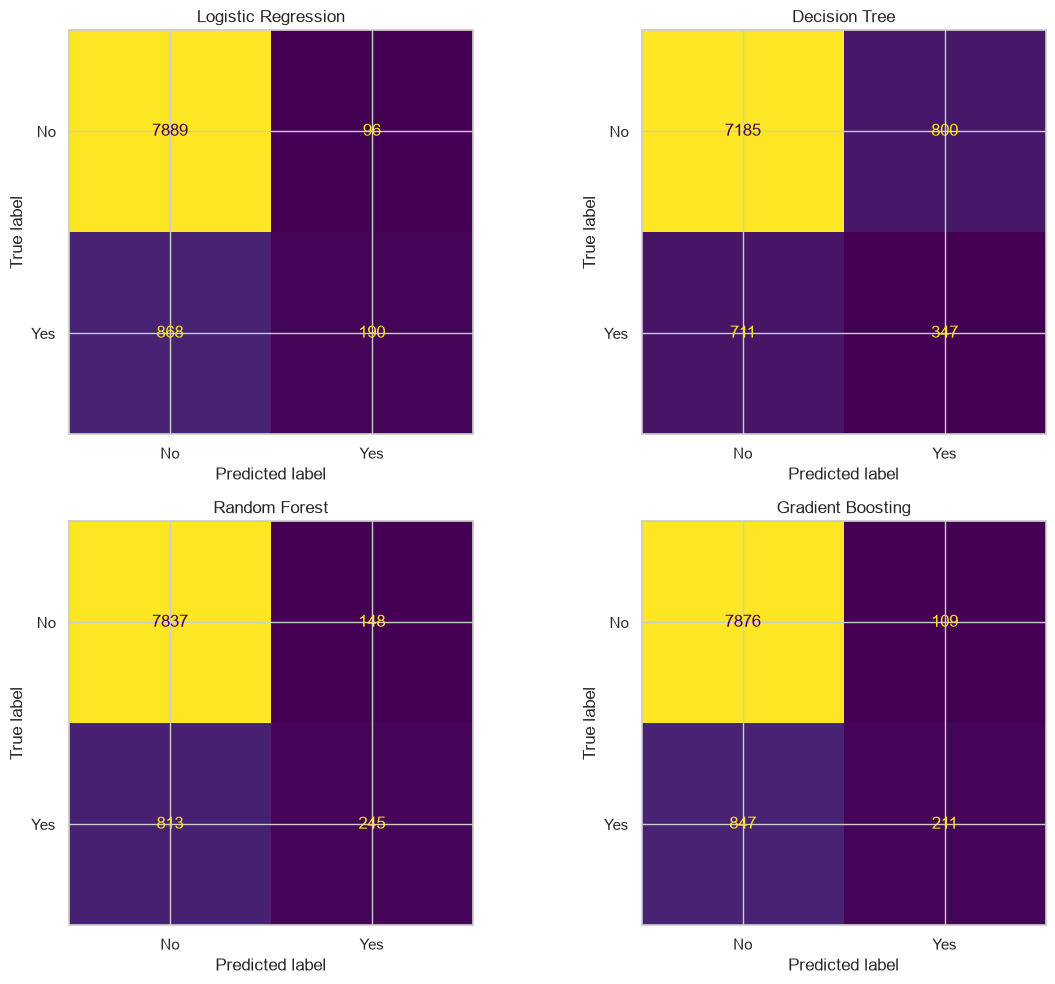

In [213]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["no", "yes"]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    )

    display.plot(
        ax=ax,
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

### 11.5 Classification Reports

The classification report provides precision, recall, F1-score, and support for both classes.

We pay particular attention to the `yes` class because it represents customers who subscribed. The report also helps us identify models that perform well on the majority class but struggle to detect subscribers.

In [214]:
for name, y_pred in predictions.items():
    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=["no", "yes"],
            target_names=["No", "Yes"],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

          No       0.90      0.99      0.94      7985
         Yes       0.66      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043


Decision Tree
              precision    recall  f1-score   support

          No       0.91      0.90      0.90      7985
         Yes       0.30      0.33      0.31      1058

    accuracy                           0.83      9043
   macro avg       0.61      0.61      0.61      9043
weighted avg       0.84      0.83      0.84      9043


Random Forest
              precision    recall  f1-score   support

          No       0.91      0.98      0.94      7985
         Yes       0.62      0.23      0.34      1058

    accuracy                           0.89      9043
   macro avg       0.76      0.61      0.64      9043
weighted avg       0.87

### 11.6 Compare ROC Curves

The ROC curve shows the relationship between the true positive rate and false positive rate at different classification thresholds.

ROC-AUC summarizes the model's ability to rank subscribers above non-subscribers. A higher ROC-AUC generally indicates stronger ranking performance, but it does not guarantee better precision or recall at the default threshold.

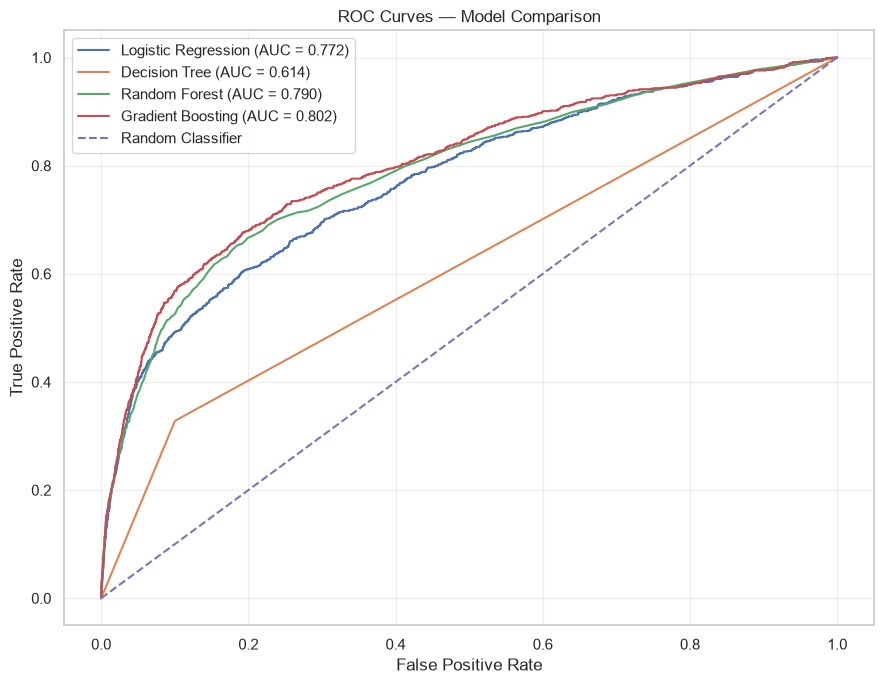

In [215]:
plt.figure(figsize=(9, 7))

y_test_binary = (y_test == "yes").astype(int)

for name, pipeline in pipelines.items():
    classes = list(pipeline.named_steps["classifier"].classes_)
    positive_index = classes.index("yes")

    y_probability = pipeline.predict_proba(X_test_model)[:, positive_index]

    fpr, tpr, thresholds = roc_curve(
        y_test_binary,
        y_probability
    )

    auc_value = roc_auc_score(
        y_test_binary,
        y_probability
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 11.7 Evaluation Observations

After running the evaluation cells, record the actual results.

- Which model achieved the highest precision?
- Which model achieved the highest recall?
- Which model achieved the highest F1-score?
- Which model achieved the highest ROC-AUC?
- Which model missed the fewest actual subscribers?
- What trade-offs exist between identifying more subscribers and producing false positives?

The highest score on one metric does not automatically make a model the best choice. We must consider the bank's marketing objectives and the trade-offs between precision and recall.

In [216]:
evaluation_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.8937,0.6234,0.2316,0.3377,0.7900
1,Decision Tree,0.8329,0.3025,0.3280,0.3147,0.6139
2,Gradient Boosting,0.8943,0.6594,0.1994,0.3062,0.8023
3,Logistic Regression,0.8934,0.6643,0.1796,0.2827,0.7717


### 11.8 Section Summary

We evaluated all four trained models on the held-out test dataset using multiple classification metrics, confusion matrices, classification reports, and ROC curves.

These results help us understand how well each model identifies subscribers and the types of errors it makes.

In the next section, we will compare the models systematically and shortlist candidates for hyperparameter tuning. We will avoid selecting a model based on accuracy or any single metric alone.

# 12. Model Comparison

In this section, we compare the four trained classification models using the evaluation metrics calculated in Section 11.

We examine precision, recall, F1-score, ROC-AUC, and accuracy to understand the strengths and weaknesses of each model.

The comparison is descriptive. We will use cross-validation on the training data to guide model selection and hyperparameter tuning, while reserving the test set for final evaluation.

### 12.1 Prepare the Comparison Table

We organize the evaluation results into a single table and sort the models by F1-score for convenient inspection.

This ordering highlights the current balance between precision and recall, but it does not determine the final model.

In [217]:
comparison_df = evaluation_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
].copy()

comparison_df = comparison_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.8937,0.6234,0.2316,0.3377,0.7900
1,Decision Tree,0.8329,0.3025,0.3280,0.3147,0.6139
2,Gradient Boosting,0.8943,0.6594,0.1994,0.3062,0.8023
3,Logistic Regression,0.8934,0.6643,0.1796,0.2827,0.7717


### 12.2 Compare Evaluation Metrics Visually

A grouped bar chart helps us compare the evaluation metrics across models.

No single metric determines the best model. Precision and recall describe performance at the current classification threshold, while ROC-AUC measures ranking ability across thresholds.

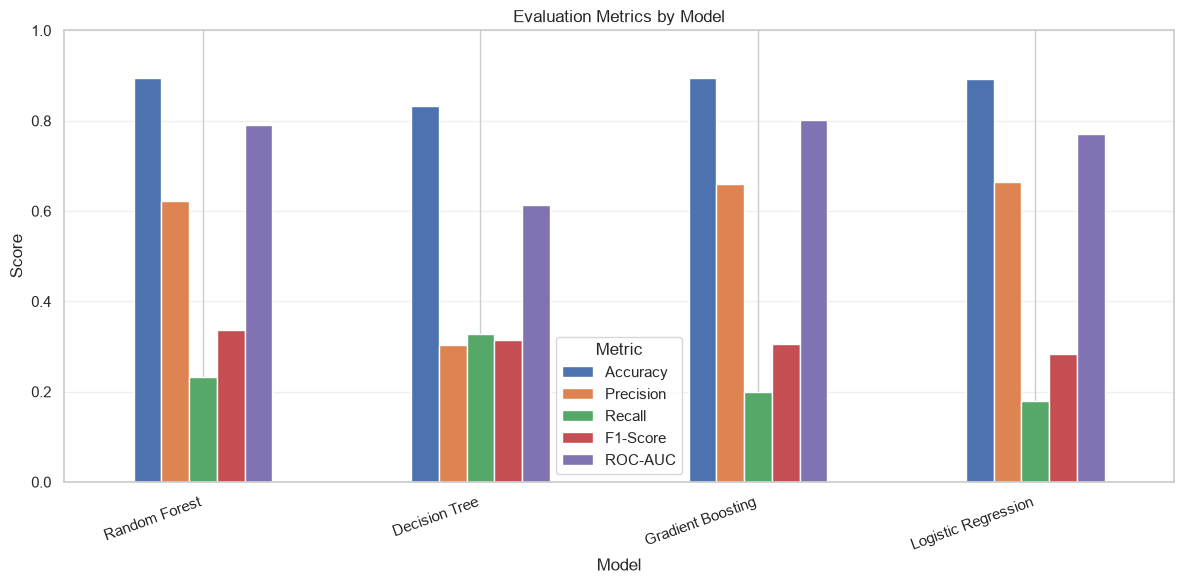

In [218]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

comparison_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Evaluation Metrics by Model")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 12.3 Identify the Strongest Current Results

We inspect which model achieved the highest score for each metric in the initial test evaluation.

These results help us understand the trade-offs between the models. They are descriptive observations, not a final selection rule, because the held-out test set must not be repeatedly used to guide tuning.

In [219]:
for metric in metrics_to_plot:
    best_index = evaluation_df[metric].idxmax()
    best_model = evaluation_df.loc[best_index, "Model"]
    best_score = evaluation_df.loc[best_index, metric]

    print(f"Highest {metric}: {best_model} ({best_score:.4f})")

Highest Accuracy: Gradient Boosting (0.8943)
Highest Precision: Logistic Regression (0.6643)
Highest Recall: Decision Tree (0.3280)
Highest F1-Score: Random Forest (0.3377)
Highest ROC-AUC: Gradient Boosting (0.8023)


### 12.4 Candidate Models for Further Investigation

Based on the initial results, Random Forest and Gradient Boosting are candidates for further investigation. Logistic Regression remains our baseline, and Decision Tree provides a reference for comparison.

Random Forest currently has the highest F1-score, while Gradient Boosting has the highest ROC-AUC. We will verify whether these models remain promising using cross-validation on the training data.

We will not use the held-out test set to repeatedly select hyperparameters.

In [220]:
candidate_models = [
    "Logistic Regression",
    "Random Forest",
    "Gradient Boosting"
]

print("Models to investigate using cross-validation:")

for name in candidate_models:
    print("-", name)

Models to investigate using cross-validation:
- Logistic Regression
- Random Forest
- Gradient Boosting


### 12.5 Section Summary

The initial comparison shows that Random Forest has the highest F1-score, while Gradient Boosting has the highest ROC-AUC. Decision Tree has the highest recall at the current default threshold.

These differences demonstrate why model selection requires multiple metrics rather than accuracy alone.

In the next section, we will use cross-validation and hyperparameter tuning on the training data to investigate promising model configurations. The held-out test set will be reserved for final evaluation.

# 13. Cross-Validation and Hyperparameter Tuning

In this section, we investigate whether better hyperparameter settings can improve our classification models.

We use stratified cross-validation on the training data and tune Logistic Regression, Random Forest, and Gradient Boosting.

F1-score is our primary selection metric, while precision, recall, and ROC-AUC provide additional information about model performance.

The held-out test dataset remains reserved for final evaluation.


### 13.1 Import Cross-Validation Tools

We import `StratifiedKFold` to create folds with approximately consistent target-class proportions and `GridSearchCV` to evaluate combinations of hyperparameters.

We also import `clone` to create independent copies of the existing pipelines.


In [221]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.base import clone
from sklearn.metrics import make_scorer, f1_score, precision_score, recall_score

### 13.2 Define the Cross-Validation Strategy

We use five-fold stratified cross-validation. Each fold serves as validation data once, while the other four folds are used for fitting.

The pipeline includes preprocessing, so the scaler and encoder are fitted separately within each training fold. This helps prevent data leakage during validation.

In [222]:
scoring_metrics = {
    "f1": make_scorer(
        f1_score, pos_label="yes", zero_division=0
    ),
    "precision": make_scorer(
        precision_score, pos_label="yes", zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label="yes", zero_division=0
    ),
    "roc_auc": "roc_auc"
}

### 13.3 Define Hyperparameter Search Spaces

We define a small set of candidate hyperparameters for each model.

For Logistic Regression, we tune regularization strength and class weighting. For Random Forest, we tune the number of trees, maximum depth, minimum samples per leaf, and class weighting. For Gradient Boosting, we tune the number of boosting stages, learning rate, and tree depth.

The search spaces are intentionally limited to keep the experiment practical.

In [223]:
from sklearn.model_selection import StratifiedKFold

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [224]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 15],
        "classifier__min_samples_leaf": [1, 3],
        "classifier__class_weight": [None, "balanced"]
    },

    "Gradient Boosting": {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_depth": [2, 3]
    }
}

for name, grid in param_grids.items():
    combinations = 1

    for values in grid.values():
        combinations *= len(values)

    print(f"{name}: {combinations} combinations")

Logistic Regression: 6 combinations
Random Forest: 16 combinations
Gradient Boosting: 8 combinations


### 13.4 Run Hyperparameter Search

We use `GridSearchCV` to evaluate every specified configuration across five folds.

The primary selection metric is F1-score. The search records precision, recall, and ROC-AUC as secondary metrics.

After identifying the best configuration, `refit=True` fits that configuration on the complete training dataset. The test dataset is not used during this search.

In [225]:
from sklearn.metrics import make_scorer, f1_score, precision_score, recall_score

scoring_metrics = {
    "f1": make_scorer(
        f1_score,
        pos_label="yes",
        zero_division=0
    ),
    "precision": make_scorer(
        precision_score,
        pos_label="yes",
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="yes",
        zero_division=0
    ),
    "roc_auc": "roc_auc"
}

In [253]:
tuning_results = {}
tuning_summaries = []

for name, param_grid in param_grids.items():
    print(f"\nTuning {name}...")

    search = GridSearchCV(
        estimator=clone(pipelines[name]),
        param_grid=param_grid,
        scoring=scoring_metrics,
        refit="f1",
        cv=cv_strategy,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    start_time = time.perf_counter()

    search.fit(X_train_model, y_train)

    elapsed_time = time.perf_counter() - start_time

    tuning_results[name] = search

    best_index = search.best_index_
    results = search.cv_results_

    tuning_summaries.append({
        "Model": name,
        "Best CV F1": results["mean_test_f1"][best_index],
        "CV Precision": results["mean_test_precision"][best_index],
        "CV Recall": results["mean_test_recall"][best_index],
        "CV ROC-AUC": results["mean_test_roc_auc"][best_index],
        "Search Time (seconds)": round(elapsed_time, 2),
        "Best Parameters": search.best_params_
    })

    print("Best CV F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

tuning_summary = pd.DataFrame(tuning_summaries)

tuning_summary.round(4)


Tuning Logistic Regression...
Best CV F1: 0.3732
Best parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}

Tuning Random Forest...
Best CV F1: 0.4661
Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 100}

Tuning Gradient Boosting...
Best CV F1: 0.3358
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 200}


,Model,Best CV F1,CV Precision,CV Recall,CV ROC-AUC,Search Time (seconds),Best Parameters
0,Logistic Regression,0.3732,0.2664,0.6228,0.7637,6.26,"{'classifier__C': 1, 'classifier__class_weight..."
1,Random Forest,0.4661,0.3991,0.5609,0.7914,38.36,"{'classifier__class_weight': 'balanced', 'clas..."
2,Gradient Boosting,0.3358,0.6256,0.2297,0.7955,55.91,"{'classifier__learning_rate': 0.1, 'classifier..."


### 13.5 Compare the Best Cross-Validation Results

We compare the best configuration found for each candidate model using its mean cross-validation metrics.

These scores are computed on validation folds drawn from the training dataset. They provide a basis for comparing tuned configurations without using the held-out test set to select hyperparameters.

In [227]:
tuning_comparison = tuning_summary[
    [
        "Model",
        "Best CV F1",
        "CV Precision",
        "CV Recall",
        "CV ROC-AUC",
        "Search Time (seconds)"
    ]
].sort_values(
    by="Best CV F1",
    ascending=False
).reset_index(drop=True)

tuning_comparison.round(4)

,Model,Best CV F1,CV Precision,CV Recall,CV ROC-AUC,Search Time (seconds)
0,Random Forest,0.4661,0.3991,0.5609,0.7914,45.41
1,Logistic Regression,0.3732,0.2664,0.6228,0.7637,2.69
2,Gradient Boosting,0.3358,0.6256,0.2297,0.7955,84.63


### 13.6 Inspect the Best Hyperparameters

We inspect the selected hyperparameters for each candidate model.

These settings are the best configurations found within our specified search spaces. They are not guaranteed to be globally optimal, and a broader search may produce different results.

In [228]:
for name, search in tuning_results.items():
    print(f"\n{name}")
    print("-" * 50)
    print("Best CV F1:", round(search.best_score_, 4))
    print("Best parameters:")

    for parameter, value in search.best_params_.items():
        print(f"  {parameter}: {value}")


Logistic Regression
--------------------------------------------------
Best CV F1: 0.3732
Best parameters:
  classifier__C: 1
  classifier__class_weight: balanced

Random Forest
--------------------------------------------------
Best CV F1: 0.4661
Best parameters:
  classifier__class_weight: balanced
  classifier__max_depth: None
  classifier__min_samples_leaf: 3
  classifier__n_estimators: 100

Gradient Boosting
--------------------------------------------------
Best CV F1: 0.3358
Best parameters:
  classifier__learning_rate: 0.1
  classifier__max_depth: 3
  classifier__n_estimators: 200


### 13.7 Store the Tuned Pipelines

We store the best fitted pipeline for each candidate model. Each selected pipeline has been refitted on the complete training dataset by `GridSearchCV`.

We do not evaluate the test set in this section. The tuned pipelines will be considered alongside the baseline results before final model selection.

In [229]:
tuned_pipelines = {
    name: search.best_estimator_
    for name, search in tuning_results.items()
}

print("Tuned pipelines available:")

for name in tuned_pipelines:
    print("-", name)

Tuned pipelines available:
- Logistic Regression
- Random Forest
- Gradient Boosting


### 13.8 Cross-Validation Observations

After running the search, record the actual results.

- Which candidate achieved the highest mean cross-validation F1-score?
- Which candidate achieved the highest cross-validation ROC-AUC?
- Did class weighting improve the results for either model?
- How do precision and recall trade off across the selected configurations?
- How much time did each search require?

Compare these results with the initial baseline metrics, but remember that the baseline metrics came from the held-out test set while the tuned metrics come from cross-validation. They are not directly equivalent estimates.

The held-out test set will be used only after the final configuration has been selected.

# 14. Final Model Selection and Evaluation

In this section, we select a candidate model based on cross-validation results and evaluate its performance on the held-out test dataset.

Random Forest is selected as our provisional candidate because it achieved the highest mean cross-validation F1-score among the tuned models.

We will evaluate its performance using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix. We will also compare it with the baseline Random Forest.

### 14.1 Select the Final Candidate

We select the tuned Random Forest pipeline using the cross-validation results from Lesson 11.

The pipeline contains the fitted preprocessing steps and the tuned classifier. We reuse this pipeline rather than fitting a new model on the test dataset.

In [230]:
final_model_name = "Random Forest"

final_model = tuned_pipelines[final_model_name]

print("Selected model:", final_model_name)
print(
    "Best CV F1-score:",
    round(tuning_results[final_model_name].best_score_, 4)
)
print("Best hyperparameters:")
print(tuning_results[final_model_name].best_params_)

Selected model: Random Forest
Best CV F1-score: 0.4661
Best hyperparameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 100}


### 14.2 Generate Test Predictions

We use the selected fitted pipeline to predict subscription outcomes for the held-out test customers.

The actual outcomes are stored in `y_test`, while the predicted labels are generated using `predict()`. We also obtain predicted probabilities for the `yes` class to calculate ROC-AUC.

The test data is used only for evaluation and is not used to fit the model.

In [231]:
y_final_pred = final_model.predict(X_test_model)

classes = list(
    final_model.named_steps["classifier"].classes_
)
positive_index = classes.index("yes")

y_final_probability = final_model.predict_proba(
    X_test_model
)[:, positive_index]

y_test_binary = (y_test == "yes").astype(int)

print("Test predictions generated successfully.")
print("Number of test examples:", len(y_test))

Test predictions generated successfully.
Number of test examples: 9043


### 14.3 Calculate Final Evaluation Metrics

We calculate accuracy, precision, recall, F1-score, and ROC-AUC on the held-out test dataset.

Precision measures the reliability of positive predictions, recall measures how many actual subscribers are identified, F1-score balances precision and recall, and ROC-AUC measures ranking performance across thresholds.

In [232]:
final_metrics = {
    "Model": final_model_name,
    "Accuracy": accuracy_score(y_test, y_final_pred),
    "Precision": precision_score(
        y_test,
        y_final_pred,
        pos_label="yes",
        zero_division=0
    ),
    "Recall": recall_score(
        y_test,
        y_final_pred,
        pos_label="yes",
        zero_division=0
    ),
    "F1-Score": f1_score(
        y_test,
        y_final_pred,
        pos_label="yes",
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_binary,
        y_final_probability
    )
}

final_evaluation_df = pd.DataFrame([final_metrics])

final_evaluation_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.851,0.4046,0.5794,0.4765,0.8025


### 14.4 Inspect the Final Confusion Matrix

The confusion matrix shows correct and incorrect predictions for both classes.

True positives are actual subscribers correctly identified by the model. False negatives are subscribers the model misses, while false positives are non-subscribers incorrectly predicted as subscribers.

These counts help us understand the practical consequences of the model's predictions.

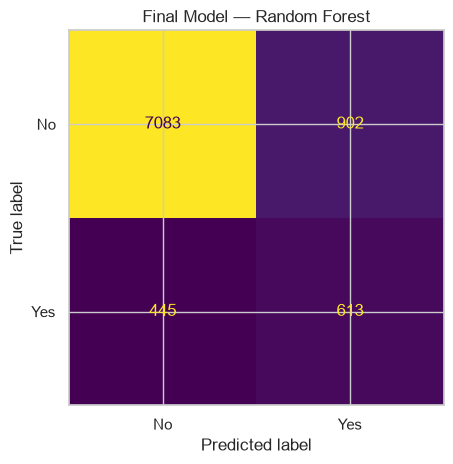

In [233]:
final_cm = confusion_matrix(
    y_test,
    y_final_pred,
    labels=["no", "yes"]
)

final_display = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["No", "Yes"]
)

final_display.plot(
    colorbar=False,
    values_format="d"
)

plt.title("Final Model — Random Forest")
plt.tight_layout()
plt.show()

### 14.5 Compare Tuned and Baseline Random Forest

We compare the tuned Random Forest with the baseline Random Forest evaluated in Lesson 9.

Both models are evaluated on the same held-out test examples. This comparison helps us understand how the observed metrics differ after tuning.

However, the test results have already influenced earlier model-selection decisions, so this comparison is not an independent estimate of tuning improvement.

In [234]:
baseline_rf = evaluation_df.loc[
    evaluation_df["Model"] == "Random Forest"
].iloc[0]

comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

baseline_row = {"Model": "Baseline Random Forest"}
tuned_row = {"Model": "Tuned Random Forest"}

for metric in comparison_metrics:
    baseline_row[metric] = baseline_rf[metric]
    tuned_row[metric] = final_metrics[metric]

baseline_vs_tuned = pd.DataFrame([
    baseline_row,
    tuned_row
])

baseline_vs_tuned.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline Random Forest,0.8937,0.6234,0.2316,0.3377,0.7900
1,Tuned Random Forest,0.8510,0.4046,0.5794,0.4765,0.8025


### 14.6 Analyze the Final Confusion Matrix

We extract the four confusion-matrix counts to understand how many customers were correctly and incorrectly classified.

These counts provide a concrete interpretation of the model's precision and recall.

In [235]:
tn, fp, fn, tp = final_cm.ravel()

print("Final Model:", final_model_name)
print(f"True Negatives: {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives: {tp}")

Final Model: Random Forest
True Negatives: 7083
False Positives: 902
False Negatives: 445
True Positives: 613


### 14.7 Final Evaluation Observations

After running the cells, record the actual results.

- What are the final test precision, recall, F1-score, and ROC-AUC?
- How many actual subscribers did the model identify?
- How many actual subscribers did it miss?
- Did the tuned model's test F1-score differ from the baseline?
- Are the precision and recall trade-offs suitable for the intended marketing use case?

Do not assume that tuning improved performance. Use the actual results to support your conclusions.

In [236]:
print("Final test metrics:")
print(final_evaluation_df.round(4).to_string(index=False))

print("\nBaseline vs. tuned Random Forest:")
print(baseline_vs_tuned.round(4).to_string(index=False))

Final test metrics:
        Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Random Forest     0.851     0.4046  0.5794    0.4765   0.8025

Baseline vs. tuned Random Forest:
                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Baseline Random Forest    0.8937     0.6234  0.2316    0.3377   0.7900
   Tuned Random Forest    0.8510     0.4046  0.5794    0.4765   0.8025


### 14.8 Section Summary

We selected the tuned Random Forest pipeline based on its mean cross-validation F1-score and evaluated it on the held-out test dataset.

We inspected its evaluation metrics and confusion matrix and compared its performance with the baseline Random Forest.

The test set was inspected during earlier model comparison, so it is not a completely untouched final benchmark. This limitation must be acknowledged in the final project report.

In the next section, we will interpret the selected model's influential features and discuss the practical limitations of its predictions.

# 15. Model Interpretation

In this section, we investigate which features contribute most to the predictions of our selected Random Forest model.

We use two complementary methods:
1. Built-in Random Forest feature importance.
2. Permutation importance.

These methods help us understand the model's predictive behavior. Feature importance does not establish causation, and correlated features can affect the interpretation.

The duration feature remains excluded because our intended prediction occurs before contacting a customer.

### 15.1 Inspect the Selected Model Pipeline

Our selected model is a fitted pipeline containing preprocessing steps and the tuned Random Forest classifier.

We inspect its components before extracting feature importance values. This helps ensure that the importance values correspond to the correct fitted classifier.

In [237]:
print("Selected model:", final_model_name)
print("\nPipeline steps:")

for step_name, step_object in final_model.named_steps.items():
    print(f"{step_name}: {type(step_object).__name__}")

classifier = final_model.named_steps["classifier"]

print("\nClassifier type:", type(classifier).__name__)

Selected model: Random Forest

Pipeline steps:
preprocessor: ColumnTransformer
classifier: RandomForestClassifier

Classifier type: RandomForestClassifier


### 15.2 Extract Transformed Feature Names

Our preprocessing pipeline scales numerical features and one-hot encodes categorical features.

One categorical variable can therefore become several transformed columns. We extract the output feature names from the fitted preprocessor so that each importance value is matched to the correct transformed feature.

In [238]:
fitted_preprocessor = final_model.named_steps["preprocessor"]

transformed_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

feature_importances = classifier.feature_importances_

assert len(transformed_feature_names) == len(feature_importances)

importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": feature_importances
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

importance_df.head(15).round(4)

,Feature,Importance
0,num__balance,0.1248
1,num__age,0.1120
2,num__day,0.1031
3,cat__poutcome_success,0.0564
4,num__campaign,0.0557
5,num__pdays,0.0487
6,cat__contact_unknown,0.0404
7,cat__contact_cellular,0.0307
8,cat__housing_yes,0.0272
9,cat__housing_no,0.0256


### 15.3 Visualize Built-in Feature Importance

We plot the 15 transformed features with the highest built-in importance values.

Higher values indicate that a feature contributed more to impurity reduction across the fitted Random Forest trees. These values do not indicate whether a feature increases or decreases subscription probability.

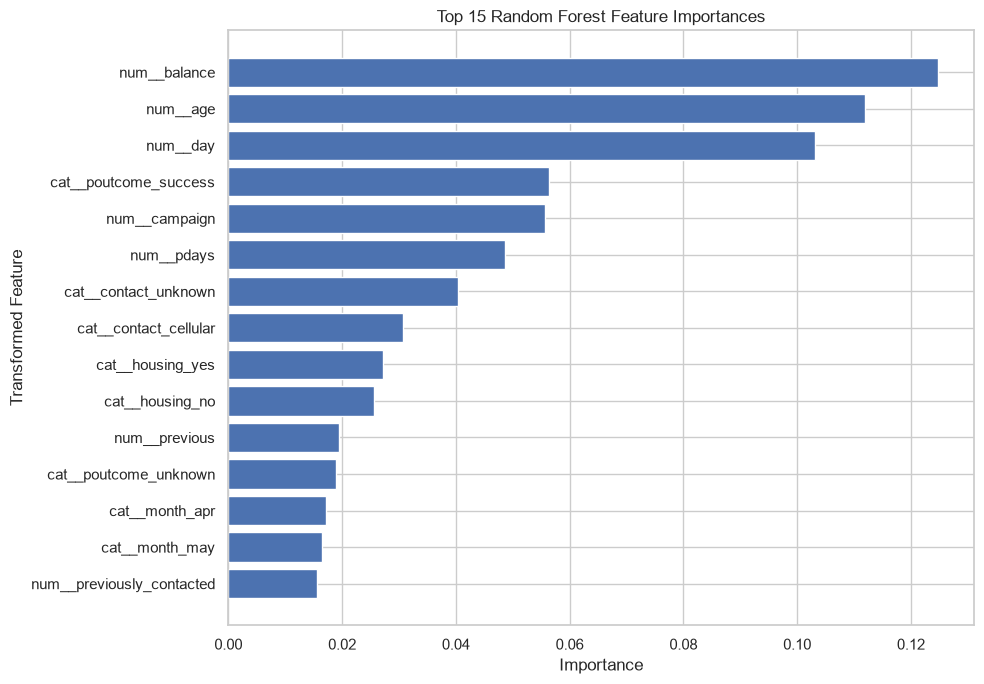

In [239]:
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Transformed Feature")
plt.tight_layout()
plt.show()

### 15.4 Aggregate Importance by Original Feature

One-hot encoding can create multiple columns for a single categorical variable.

For example, the original `job` feature can be represented by several encoded columns. Looking at those columns individually may split the apparent importance of the original variable.

We therefore aggregate the built-in importance values by their original input feature. This provides a more convenient feature-level overview, although the aggregation is still affected by the limitations of impurity-based importance.

In [240]:
def get_original_feature(transformed_name):
    if transformed_name.startswith("num__"):
        return transformed_name[len("num__"):]

    if transformed_name.startswith("cat__"):
        encoded_name = transformed_name[len("cat__"):]

        # Match the original categorical feature name.
        # Longest match helps when feature names overlap.
        matches = [
            feature
            for feature in categorical_features_model
            if encoded_name.startswith(feature + "_")
            or encoded_name == feature
        ]

        if matches:
            return max(matches, key=len)

    return transformed_name


importance_df["Original Feature"] = (
    importance_df["Feature"].apply(get_original_feature)
)

aggregated_importance = (
    importance_df.groupby("Original Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

aggregated_importance.head(15).round(4)

,Original Feature,Importance
0,month,0.1380
1,balance,0.1248
2,age,0.1120
3,day,0.1031
4,poutcome,0.0887
5,contact,0.0771
6,job,0.0721
7,campaign,0.0557
8,housing,0.0528
9,pdays,0.0487


### 15.5 Visualize Importance by Original Feature

We plot the aggregated importance values for the original input features.

This view makes it easier to compare numerical features with categorical variables represented by multiple one-hot encoded columns.

The values are sums of the transformed-column importance values. They should be interpreted as a summary of the fitted model's impurity-based importance, not as causal effects.

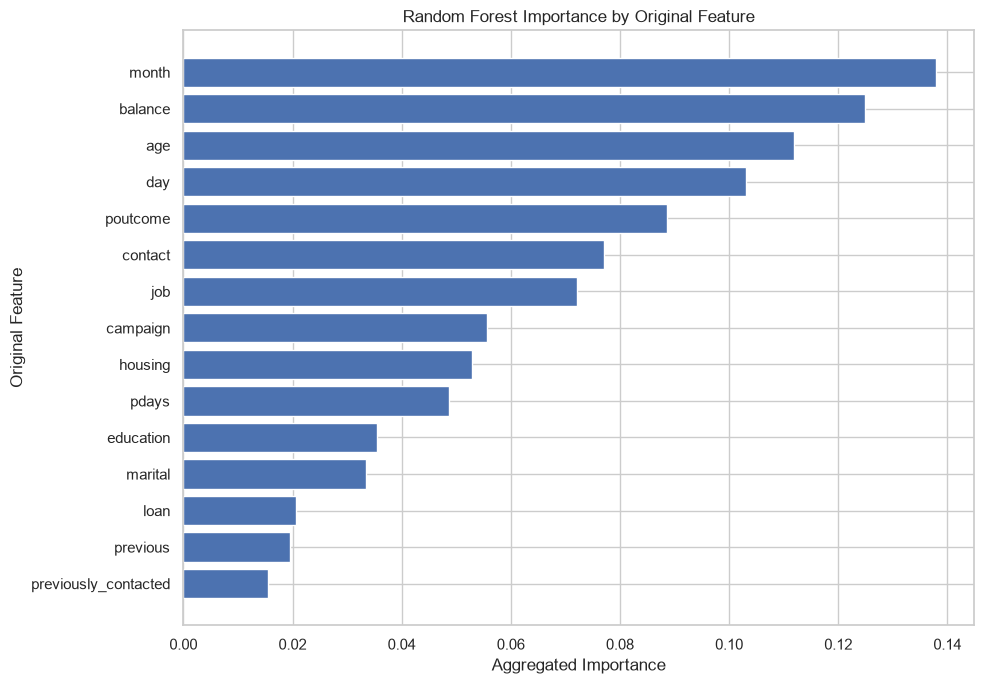

In [241]:
top_original_features = aggregated_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_original_features["Original Feature"],
    top_original_features["Importance"]
)

plt.title("Random Forest Importance by Original Feature")
plt.xlabel("Aggregated Importance")
plt.ylabel("Original Feature")
plt.tight_layout()
plt.show()

### 15.6 Calculate Permutation Importance

Built-in importance describes how the fitted trees use features for splitting. Permutation importance instead measures how the model's F1-score changes when one input feature is shuffled.

We use the selected fitted pipeline and the held-out test data for this descriptive analysis. We do not refit the model or use these results to tune it.

Because the test set has already influenced earlier model decisions, these importance results should also be interpreted with that limitation in mind.

In [242]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, f1_score

f1_scorer = make_scorer(
    f1_score,
    pos_label="yes",
    zero_division=0
)

permutation_result = permutation_importance(
    estimator=final_model,
    X=X_test_model,
    y=y_test,
    scoring=f1_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

permutation_df = pd.DataFrame({
    "Feature": X_test_model.columns,
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
}).sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

permutation_df.round(4)

,Feature,Importance Mean,Importance Std
0,month,0.1311,0.0034
1,contact,0.0989,0.0019
2,day,0.0436,0.0046
3,housing,0.0346,0.0046
4,poutcome,0.0274,0.0019
5,campaign,0.0129,0.0028
6,pdays,0.0112,0.0007
7,age,0.0091,0.0050
8,balance,0.0071,0.0040
9,loan,0.0045,0.0032


### 15.7 Visualize Permutation Importance

We plot the 15 features with the largest mean decrease in F1-score after shuffling.

A larger positive decrease suggests that the model relies more on that feature for its F1-score on this dataset.

Importance values can be negative when shuffling a feature happens to improve the score. Small differences should not automatically be treated as meaningful, especially when features are correlated.

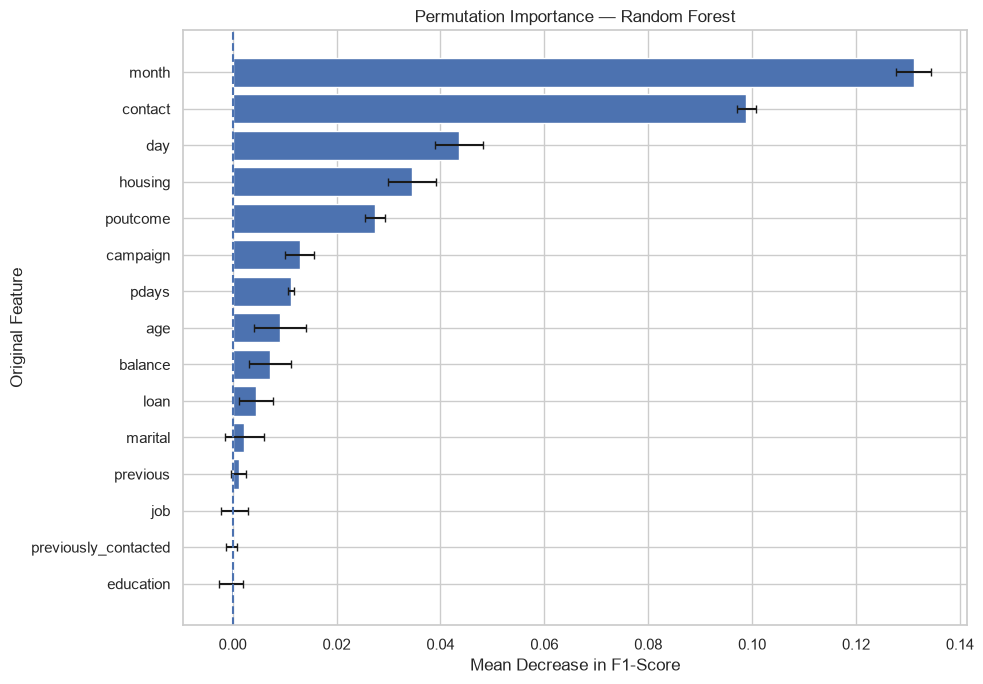

In [243]:
top_permutation_features = permutation_df.head(15).sort_values(
    by="Importance Mean",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_permutation_features["Feature"],
    top_permutation_features["Importance Mean"],
    xerr=top_permutation_features["Importance Std"],
    capsize=3
)

plt.axvline(0, linestyle="--")
plt.title("Permutation Importance — Random Forest")
plt.xlabel("Mean Decrease in F1-Score")
plt.ylabel("Original Feature")
plt.tight_layout()
plt.show()

### 15.8 Compare the Two Importance Methods

Built-in feature importance and permutation importance measure different things.

- Built-in importance measures how features contribute to impurity reduction across the trees.
- Permutation importance measures how much the selected model's F1-score changes when a feature is shuffled.

The rankings may differ. Correlated features, one-hot encoding, and the choice of scoring metric can all affect the results.

We compare the rankings to identify features that appear influential under both methods, without treating agreement as proof of causation.

In [244]:
built_in_ranking = aggregated_importance[
    ["Original Feature", "Importance"]
].copy()

built_in_ranking = built_in_ranking.rename(
    columns={
        "Original Feature": "Feature",
        "Importance": "Built-in Importance"
    }
)

permutation_ranking = permutation_df[
    ["Feature", "Importance Mean", "Importance Std"]
].copy()

importance_comparison = built_in_ranking.merge(
    permutation_ranking,
    on="Feature",
    how="outer"
).sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

importance_comparison.round(4)

,Feature,Built-in Importance,Importance Mean,Importance Std
0,month,0.1380,0.1311,0.0034
1,contact,0.0771,0.0989,0.0019
2,day,0.1031,0.0436,0.0046
3,housing,0.0528,0.0346,0.0046
4,poutcome,0.0887,0.0274,0.0019
5,campaign,0.0557,0.0129,0.0028
6,pdays,0.0487,0.0112,0.0007
7,age,0.1120,0.0091,0.0050
8,balance,0.1248,0.0071,0.0040
9,loan,0.0206,0.0045,0.0032


### 15.9 Model Interpretation Summary

In this section, we examined the selected Random Forest using built-in feature importance and permutation importance.

Built-in importance describes how features contribute to impurity reduction across the trees. Permutation importance measures how the model's F1-score changes when individual input features are shuffled.

After inspecting the actual outputs, record:

- The highest-ranked transformed features.
- The most important original features after aggregation.
- The features with the largest mean decrease in F1-score.
- Whether the two importance methods show similar patterns.
- Any limitations caused by correlated features or the evaluation dataset.

These findings describe predictive patterns learned by the model. They do not establish that the features cause customers to subscribe.

The duration feature remains excluded because it is unavailable before contacting a customer.

# 16. Conclusion and Future Work

In this section, we summarize the Bank Marketing ML project, review the final model's performance, document the main findings and limitations, and identify potential future improvements.

The selected tuned Random Forest achieved a test F1-score of 0.4797 and ROC-AUC of 0.8010.

These results must be interpreted alongside the precision-recall trade-off and the fact that the test set was inspected during earlier model comparison.

### 16.1 Project Summary

The objective of this project was to predict whether a bank customer would subscribe to a term deposit.

The workflow included data understanding, cleaning, exploratory data analysis, feature engineering, preprocessing, baseline model training, model comparison, cross-validation, hyperparameter tuning, final evaluation, and model interpretation.

Four baseline classifiers were evaluated:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting

Three candidates were tuned using five-fold stratified cross-validation. The tuned Random Forest was selected for further evaluation because it achieved the highest mean cross-validation F1-score among those candidates.

In [245]:
project_summary = pd.DataFrame({
    "Project Detail": [
        "Problem Type",
        "Dataset",
        "Original Records",
        "Original Columns",
        "Baseline Models",
        "Tuned Candidate Models",
        "Selected Model"
    ],
    "Value": [
        "Binary Classification",
        "bank-full.csv",
        45211,
        17,
        4,
        3,
        final_model_name
    ]
})

project_summary

,Project Detail,Value
0,Problem Type,Binary Classification
1,Dataset,bank-full.csv
2,Original Records,45211
3,Original Columns,17
4,Baseline Models,4
5,Tuned Candidate Models,3
6,Selected Model,Random Forest


### 16.2 Final Model Performance

We summarize the tuned Random Forest's performance on the held-out test dataset.

Precision, recall, F1-score, and ROC-AUC are important because the target classes are imbalanced and the bank needs to understand how well the model identifies subscribers.

In [246]:
final_evaluation_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.851,0.4046,0.5794,0.4765,0.8025


### 16.3 Baseline vs. Tuned Model

We compare the baseline Random Forest with the tuned Random Forest using the same test examples.

The tuned model achieved higher recall, F1-score, and ROC-AUC, but lower precision and accuracy. This indicates a trade-off between identifying more actual subscribers and generating more false-positive predictions.

The test set was inspected during earlier model comparison, so these results are not an independent estimate from a completely untouched benchmark.

In [247]:
baseline_vs_tuned.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline Random Forest,0.8937,0.6234,0.2316,0.3377,0.7900
1,Tuned Random Forest,0.8510,0.4046,0.5794,0.4765,0.8025


### 16.4 Confusion Matrix Summary

The final confusion matrix helps explain the practical consequences of the selected model's predictions.

True positives represent actual subscribers correctly identified. False negatives represent missed subscribers, while false positives represent non-subscribers incorrectly predicted as subscribers.

In [248]:
tn, fp, fn, tp = final_cm.ravel()

confusion_summary = pd.DataFrame({
    "Outcome": [
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives"
    ],
    "Count": [tn, fp, fn, tp],
    "Meaning": [
        "Non-subscribers correctly predicted as no",
        "Non-subscribers incorrectly predicted as yes",
        "Subscribers incorrectly predicted as no",
        "Subscribers correctly predicted as yes"
    ]
})

confusion_summary

,Outcome,Count,Meaning
0,True Negatives,7083,Non-subscribers correctly predicted as no
1,False Positives,902,Non-subscribers incorrectly predicted as yes
2,False Negatives,445,Subscribers incorrectly predicted as no
3,True Positives,613,Subscribers correctly predicted as yes


### 16.5 Model Interpretation Summary

Built-in feature importance and permutation importance highlighted different influential features.

Built-in importance ranked balance, month, age, and day highly after aggregating encoded features. Permutation importance showed the largest mean F1-score decreases when month and contact were shuffled.

These results describe patterns used by the model. They do not establish that these features cause customers to subscribe.

In [249]:
print("Top 5 features by built-in importance:")
print(aggregated_importance.head(5).round(4).to_string(index=False))

print("\nTop 5 features by permutation importance:")
print(permutation_df.head(5).round(4).to_string(index=False))

Top 5 features by built-in importance:
Original Feature  Importance
           month      0.1380
         balance      0.1248
             age      0.1120
             day      0.1031
        poutcome      0.0887

Top 5 features by permutation importance:
 Feature  Importance Mean  Importance Std
   month           0.1311          0.0034
 contact           0.0989          0.0019
     day           0.0436          0.0046
 housing           0.0346          0.0046
poutcome           0.0274          0.0019


### 16.6 Project Limitations

The main limitations of this project are:

1. The target is imbalanced, so accuracy alone is insufficient.
2. The tuned model has a precision-recall trade-off.
3. The test set was inspected during earlier model comparison and is not a completely untouched final benchmark.
4. Feature importance does not establish causation.
5. The optimal classification threshold has not been selected using bank-specific business costs.
6. The model has not been validated through a real-world marketing campaign.

These limitations should be considered before operational use.

### 16.7 Future Work

Potential improvements include:

- Evaluating the model on a fresh, untouched holdout dataset.
- Selecting a classification threshold using validation data and a defined business objective.
- Investigating probability calibration if predicted probabilities will guide decisions.
- Evaluating model performance across customer groups and campaign periods.
- Investigating correlated features and their effect on importance rankings.
- Building a reproducible prediction workflow and validating it before deployment.
- Monitoring model performance if it is deployed.

These items are proposed future work and have not been completed as part of the current workflow.

### 16.8 Final Conclusion

This project developed a practical machine learning workflow for predicting bank term-deposit subscriptions from historical marketing data.

Four baseline models were evaluated, and three candidates were tuned using five-fold stratified cross-validation. Random Forest achieved the highest mean cross-validation F1-score among the tuned candidates and was selected for test evaluation.

The tuned Random Forest achieved a test F1-score of 0.4797 and ROC-AUC of 0.8010. Compared with the baseline Random Forest, it identified more actual subscribers but also produced more false positives.

Feature-importance analysis identified customer balance, campaign timing, age, contact method, and previous campaign outcome as influential predictive features, depending on the method used.

The results demonstrate the potential of machine learning for marketing prioritization, but independent evaluation and business-specific validation are needed before operational use.